# STEP 10. Going deeper: separating openings and closures · cell fixed effects · foot-traffic composition

STEP 9 ended with two conclusions.

- Store count is by far the top variable, but a large part of that is label arithmetic
- Foot traffic disappears once store count is controlled for (mediation)

Both conclusions come from looking at a single outcome, **the sign of the net change**. Here we add three more analyses.

| Section | What | Why |
|---|---|---|
| 10-2 | **Separate openings and closures** | "Net decline because there are no openings" and "net decline because there are many closures" are completely different phenomena |
| 10-3 | **Commercial area x service category fixed effects** | Remove time-invariant confounders such as rent, location and commercial-area character in one go |
| 10-4 | **Foot-traffic composition x service category interaction** | Composition, not total volume. The same value can have a different slope for each service category |

## Why these three

`y = [opening(t+1) − closure(t+1) < 0]` is the **difference between two flows**. If a variable moves openings and closures **in the same direction**, the effects cancel in the difference and the variable looks "unrelated". 10-2 opens that up.

The 21 detailed foot-traffic columns (gender 2 · age 6 · time of day 6 · day of week 7) are still in `01_flow.pkl`. **As levels they correlate 0.95-0.997 with the total and add nothing; converting them to shares creates a new dimension.**

Required packages: the existing ones + `statsmodels` (conditional Poisson / negative binomial)

In [1]:
import sys, os
from pathlib import Path

# Find the project root wherever the notebook is opened and add it to sys.path
ROOT = Path.cwd()
while not (ROOT / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

# If the kernel is not restarted after editing config.py, Python keeps the old module cached.
import importlib
if "config" in sys.modules:
    importlib.reload(sys.modules["config"])

import numpy as np
import pandas as pd
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
print("Project root:", ROOT.name)

Project root: seoul-closure-risk


In [2]:
import warnings
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.discrete.conditional_models import ConditionalPoisson, ConditionalLogit
from config import (SVC_ORDER, dummies, PROC, FIG, TARGET_TYPE, TREAT_SVC, TRAIN_QUARTERS,
                    build_features, set_plot_style)
set_plot_style()
warnings.filterwarnings("ignore")
OUT = FIG.parent
REF_SVC = TREAT_SVC        # service category reference = Korean restaurants

# ── Load originals (_raw preserved) ───────────────────────
panel_raw = pd.read_pickle(PROC / "03_panel.pkl")
flow_raw  = pd.read_pickle(PROC / "01_flow.pkl")
merged_raw = pd.read_pickle(PROC / "02_merged.pkl")

print(f"panel  {panel_raw.shape}")
print(f"flow   {flow_raw.shape}  <- unused detailed columns are here")
print(f"merged {merged_raw.shape}  <- original before filtering (for looking up next-quarter openings/closures)")

panel  (67475, 34)
flow   (21434, 11)  <- unused detailed columns are here
merged (160352, 23)  <- original before filtering (for looking up next-quarter openings/closures)


## 10-1. Build the filtered working copy

Same principle as STEP 1: leave `_raw` untouched, **cut to the needed range first, then work on a `.copy()`**.

- Scope: **neighborhood commercial areas · training quarters (20231-20253)**
- The validation quarter (20254) and the prediction quarter (20261) are excluded. Conclusions drawn here feed the STEP 8 prediction, so this prevents leakage

In [3]:
# ① Cut to the analysis scope first
gm = panel_raw[(panel_raw["area_type"] == TARGET_TYPE) &
               (panel_raw["quarter_code"].isin(TRAIN_QUARTERS))].copy()
gm = build_features(gm)
areas = np.unique(gm["area_code"].to_numpy())
print(f"Working copy {len(gm):,} rows | commercial areas {len(areas)} | quarters {gm['quarter_code'].nunique()}")
assert 20254 not in gm["quarter_code"].values, "Validation quarter is mixed in"

# ② Next-quarter opening/closure counts: taken from the original before filtering (avoids selection bias)
nx = merged_raw.copy()
nx["quarter_idx"] = nx["quarter_code"].map(lambda x: (x // 10) * 4 + (x % 10 - 1))
nx = nx[["area_code", "service_code", "quarter_idx", "opening_count", "closure_count"]] \
       .rename(columns={"opening_count": "opening_n", "closure_count": "closure_n"})

gm = gm.assign(nxt=gm["quarter_idx"] + 1).merge(
    nx, left_on=["area_code", "service_code", "nxt"],
    right_on=["area_code", "service_code", "quarter_idx"],
    how="left", suffixes=("", "_r"), validate="many_to_one")
assert gm["opening_n"].isna().sum() == 0, "Some rows have no next-quarter count"
print(f"Next-quarter counts merged: 0 missing")

Working copy 31,875 rows | commercial areas 925 | quarters 11
Next-quarter counts merged: 0 missing


### Deriving foot-traffic composition shares

The key is to build **shares, not levels**. First we check why.

In [4]:
fl = flow_raw[flow_raw["area_code"].isin(areas) &
              flow_raw["quarter_code"].isin(TRAIN_QUARTERS)].copy()
tot = fl["foot_traffic_total"].replace(0, np.nan)

print("[Used as levels, how much do they overlap with the total?]")
for c in ["foot_traffic_time_11_14", "foot_traffic_time_17_21",
          "foot_traffic_age_20", "foot_traffic_sat"]:
    r = np.corrcoef(np.log1p(fl[c]), np.log1p(tot))[0, 1]
    print(f"  {c:26} r = {r:.4f}")
print("-> 0.95-0.997. A busy commercial area is busy in the evening and on Saturday too. No new information.\n")

share = pd.DataFrame({
    "quarter_code": fl["quarter_code"], "area_code": fl["area_code"],
    "lunch_share": fl["foot_traffic_time_11_14"] / tot,
    "dinner_share": fl["foot_traffic_time_17_21"] / tot,
    "late_night_share": fl["foot_traffic_time_21_24"] / tot,
    "youth_share": (fl["foot_traffic_age_20"] + fl["foot_traffic_age_30"]) / tot,
    "senior_share": fl["foot_traffic_age_60_plus"] / tot,
    "weekend_share": (fl["foot_traffic_sat"] + fl["foot_traffic_sun"]) / tot,
})
SHARES = [c for c in share.columns if c.endswith("_share")]

print("[Converted to shares]")
rows = []
for c in SHARES:
    v = share[c]
    btw = share.groupby("area_code")[c].transform("mean").var() / v.var()
    rows.append({"composition_share": c, "corr_with_total": np.corrcoef(v, np.log1p(tot))[0, 1],
                 "5%": v.quantile(.05), "95%": v.quantile(.95),
                 "between_area_variance": btw, "within_area_variance": 1 - btw})
display(pd.DataFrame(rows).round(3))
print("-> Correlation with the total is -0.4 to +0.42. It captures the 'character of the commercial area', not scale.")

gm = gm.merge(share, on=["quarter_code", "area_code"], how="left", validate="many_to_one")
gm["cell"] = gm["area_code"].astype(str) + "_" + gm["service_code"]
print(f"\nFinal working copy {gm.shape} | composition shares missing {gm[SHARES].isna().sum().sum()}")

[Used as levels, how much do they overlap with the total?]


  foot_traffic_time_11_14    r = 0.9874
  foot_traffic_time_17_21    r = 0.9911
  foot_traffic_age_20        r = 0.9480
  foot_traffic_sat           r = 0.9966
-> 0.95-0.997. A busy commercial area is busy in the evening and on Saturday too. No new information.

[Converted to shares]


,composition_share,corr_with_total,5%,95%,between_area_variance,within_area_variance
0,lunch_share,-0.409,0.097,0.165,0.949,0.051
1,dinner_share,-0.142,0.135,0.208,0.946,0.054
2,late_night_share,0.422,0.099,0.143,0.964,0.036
3,youth_share,0.146,0.216,0.518,0.990,0.010
4,senior_share,-0.015,0.124,0.308,0.977,0.023
5,weekend_share,0.109,0.243,0.311,0.866,0.134


-> Correlation with the total is -0.4 to +0.42. It captures the 'character of the commercial area', not scale.

Final working copy (31875, 50) | composition shares missing 0


## 10-2. Separate openings and closures ★

`y` is the **difference** between two flows. Modeling them separately splits the blurred signal apart.

### Model choice

- **Outcome** — number of openings / number of closures in the next quarter (counts)
- **Offset** — `log(store_count)`. More stores naturally means more events, so it is included to model a **rate rather than a count**
- **Distribution** — if the data are overdispersed (variance > mean), use negative binomial instead of Poisson. Checked below
- **Standard errors** — clustered by commercial area

The label-arithmetic problem (STEP 9) also disappears here automatically. "Nothing happened" is no longer blurred into `y=0`; it enters as **a count of 0**.

In [5]:
print("[Overdispersion check]")
for c, nm in [("opening_n", "opening"), ("closure_n", "closure")]:
    print(f"  {nm}  mean {gm[c].mean():.3f}  variance {gm[c].var():.3f}  "
          f"ratio {gm[c].var()/gm[c].mean():.2f}")
print("-> Variance/mean > 1 means overdispersion. Poisson underestimates standard errors, so negative binomial is used.\n")

X = pd.concat([
    gm[["log_store_count", "log_foot_traffic", "log_area_size", "log_attracting_facilities",
        "food_service_share", "franchise_share"]],
    dummies(gm["service_name"], prefix="svc")
      .drop(columns=[f"svc_{REF_SVC}"]),
    dummies(gm["district"], prefix="gu", drop_first=True),
    pd.get_dummies(gm["quarter_code"], prefix="q", drop_first=True),
], axis=1).astype(float)
X = sm.add_constant(X)
offset = np.log(gm["store_count"])

def negbin(yv):
    return sm.GLM(gm[yv], X, family=sm.families.NegativeBinomial(alpha=1.0),
                  offset=offset).fit(cov_type="cluster",
                                     cov_kwds={"groups": gm["area_code"].values})

m_open, m_close = negbin("opening_n"), negbin("closure_n")
show = [c for c in X.columns if not c.startswith(("gu_", "q_"))]
cmp = pd.DataFrame({
    "opening_coef": m_open.params, "opening_p": m_open.pvalues,
    "closure_coef": m_close.params, "closure_p": m_close.pvalues,
}).loc[show]
cmp["direction"] = np.where(np.sign(cmp["opening_coef"]) != np.sign(cmp["closure_coef"]), "opposite", "same")
display(cmp.round(3))
print(f"n = {len(gm):,} | district dummies {sum(c.startswith('gu_') for c in X.columns)}, "
      f"quarter dummies {sum(c.startswith('q_') for c in X.columns)} omitted")

[Overdispersion check]
  opening  mean 0.530  variance 0.959  ratio 1.81
  closure  mean 0.598  variance 0.984  ratio 1.65
-> Variance/mean > 1 means overdispersion. Poisson underestimates standard errors, so negative binomial is used.



,opening_coef,opening_p,closure_coef,closure_p,direction
const,-5.005,0.000,-3.393,0.000,same
log_store_count,-0.099,0.000,0.065,0.001,opposite
log_foot_traffic,0.098,0.000,0.053,0.010,same
log_area_size,0.074,0.057,-0.040,0.191,opposite
log_attracting_facilities,-0.023,0.400,-0.065,0.001,same
food_service_share,0.472,0.002,-0.484,0.000,opposite
franchise_share,0.189,0.029,0.029,0.699,same
svc_Korean snack-food restaurants,-0.223,0.000,0.283,0.000,opposite
svc_Western restaurants,-0.191,0.002,0.240,0.000,opposite
svc_Japanese restaurants,-0.309,0.000,0.267,0.000,opposite


n = 31,875 | district dummies 24, quarter dummies 10 omitted


### What split apart

If the **signs of the two coefficients are opposite**, the effect is amplified in the net change; if **the same, it cancels**. The variables that cancel are exactly those that "look unrelated when viewed as net decline but actually act strongly".

In [6]:
cmp2 = cmp[cmp.index != "const"].copy()
cmp2["net_change_contribution"] = cmp2["opening_coef"] - cmp2["closure_coef"]   # opening up / closure down means net increase
cmp2["offset_ratio"] = 1 - cmp2["net_change_contribution"].abs() / (
    cmp2["opening_coef"].abs() + cmp2["closure_coef"].abs()).replace(0, np.nan)
sig = cmp2[(cmp2["opening_p"] < .05) | (cmp2["closure_p"] < .05)]

print("[Variables with large cancellation: what a single net-decline outcome misses]")
display(sig.sort_values("offset_ratio", ascending=False)
        [["opening_coef", "opening_p", "closure_coef", "closure_p", "net_change_contribution", "offset_ratio"]].round(3))
print("Note: the closer offset_ratio is to 1, the more the variable pushes openings and closures in the same direction,")
print("   so its effect vanishes in the net change (difference).")

[Variables with large cancellation: what a single net-decline outcome misses]


,opening_coef,opening_p,closure_coef,closure_p,net_change_contribution,offset_ratio
log_foot_traffic,0.098,0.000,0.053,0.010,0.045,0.702
log_attracting_facilities,-0.023,0.400,-0.065,0.001,0.042,0.518
franchise_share,0.189,0.029,0.029,0.699,0.160,0.266
log_store_count,-0.099,0.000,0.065,0.001,-0.164,0.000
food_service_share,0.472,0.002,-0.484,0.000,0.956,0.000
svc_Korean snack-food restaurants,-0.223,0.000,0.283,0.000,-0.506,0.000
svc_Western restaurants,-0.191,0.002,0.240,0.000,-0.431,0.000
svc_Japanese restaurants,-0.309,0.000,0.267,0.000,-0.576,0.000
svc_Bakeries,-0.385,0.000,0.194,0.001,-0.579,0.000
svc_Chinese restaurants,-0.231,0.001,0.304,0.000,-0.535,0.000


Note: the closer offset_ratio is to 1, the more the variable pushes openings and closures in the same direction,
   so its effect vanishes in the net change (difference).


## 10-3. Commercial area x service category fixed effects

Giving each cell its own intercept removes **everything that does not change over time**: rent, location, commercial-area character, building condition, even the average ability of the owners in that cell. It fills much of the gap left by the rent data we could not attach.

In exchange, **service category effects cannot be identified.** A Korean-restaurant cell is Korean restaurants for all 11 quarters, so it does not vary within the cell. This section is **only for sub-question 2**.

### Why conditional Poisson rather than conditional logistic

First we apply cell fixed effects to whether there is a net decline (`y`). The problem shows up here.

In [7]:
TV_LOGIT = ["log_store_count", "log_foot_traffic", "food_service_share", "opening_rate", "closure_rate",
            "lunch_share", "dinner_share", "youth_share"]
qd = pd.get_dummies(gm["quarter_code"], prefix="q", drop_first=True).astype(float)

dl = gm.dropna(subset=TV_LOGIT).copy()
Xl = pd.concat([dl[TV_LOGIT].astype(float), qd.loc[dl.index]], axis=1)
Xl = (Xl - Xl.mean()) / Xl.std().replace(0, 1)      # standardize, because scale differences cause convergence failure

cl = ConditionalLogit(dl["y"].astype(int).values, Xl.values,
                      groups=dl["cell"].values).fit(disp=0)
display(pd.DataFrame({"coef_standardized": cl.params, "p_value": cl.pvalues},
                     index=Xl.columns).loc[TV_LOGIT].round(4))
print(f"n = {int(cl.nobs):,} (cells where y does not vary within the cell are excluded automatically)")
print()
print("⚠️ The log_store_count coefficient is abnormally large on a standardized basis.")
print("   Store count (stock) predicts its own change (flow), so mean reversion creeps in:")
print("   a time point with more stores than the cell average is likely to decline next. That is arithmetic, not causation.")
print("   This term shakes the other coefficients too, so below store count is moved into the offset.")

,coef_standardized,p_value
log_store_count,5.6561,0.0000
log_foot_traffic,0.1965,0.2210
food_service_share,0.1938,0.2096
opening_rate,-0.0951,0.0000
closure_rate,0.0498,0.0062
lunch_share,0.3054,0.0107
dinner_share,-0.1566,0.0669
youth_share,0.0092,0.9578


n = 28,667 (cells where y does not vary within the cell are excluded automatically)

⚠️ The log_store_count coefficient is abnormally large on a standardized basis.
   Store count (stock) predicts its own change (flow), so mean reversion creeps in:
   a time point with more stores than the cell average is likely to decline next. That is arithmetic, not causation.
   This term shakes the other coefficients too, so below store count is moved into the offset.


### Conditional Poisson: store count as the offset

Use the same cell fixed effects, but make the outcome the **opening / closure counts** and move store count to the **offset**. Store count then becomes a denominator rather than a regressor, and the stock-flow artifact disappears.

How to read it: **"In quarters when this variable is higher than usual within the same cell, how does the opening (closure) rate change."**

In [8]:
TV_FE = ["log_foot_traffic", "food_service_share", "lunch_share", "dinner_share", "youth_share", "weekend_share"]

def cond_poisson(yv):
    d = gm.dropna(subset=TV_FE + [yv]).copy()
    Xf = pd.concat([d[TV_FE].astype(float), qd.loc[d.index]], axis=1)
    Xf = (Xf - Xf.mean()) / Xf.std().replace(0, 1)
    m = ConditionalPoisson(d[yv].values, Xf.values, groups=d["cell"].values,
                           offset=np.log(d["store_count"]).values).fit(disp=0)
    return pd.Series(m.params, index=Xf.columns), pd.Series(m.pvalues, index=Xf.columns), int(m.nobs)

bo, po, no = cond_poisson("opening_n")
bc, pc, nc = cond_poisson("closure_n")
fe = pd.DataFrame({"opening_coef": bo, "opening_p": po,
                   "closure_coef": bc, "closure_p": pc}).loc[TV_FE]
display(fe.round(4))
print(f"Opening model n = {no:,} | closure model n = {nc:,}")
print()
print("Note: time-invariant variables (log_area_size, service category, district) are absorbed by the cell fixed effects and drop out.")

,opening_coef,opening_p,closure_coef,closure_p
log_foot_traffic,0.0158,0.8650,0.0040,0.9628
food_service_share,-0.9122,0.0000,0.9722,0.0000
lunch_share,0.0440,0.5726,0.0290,0.6512
dinner_share,-0.0236,0.6438,-0.0790,0.0844
youth_share,0.2238,0.0229,0.0860,0.3535
weekend_share,-0.0730,0.1761,-0.0769,0.1297


Opening model n = 28,269 | closure model n = 30,046

Note: time-invariant variables (log_area_size, service category, district) are absorbed by the cell fixed effects and drop out.


## 10-4. Foot-traffic composition x service category interaction

Limitation ② of STEP 9: foot traffic is at the commercial-area level, so all 10 service categories in the same commercial area receive **the same value**. That is why differences between service categories could not be explained.

**With interactions, the slope differs even when the value is the same.** The same "evening share 20%" can favor a pub and be irrelevant to a bakery.

The reference category is Korean restaurants, and the values in the tables are **each service category's total slope** (main effect + interaction). Composition shares are standardized to 1 standard deviation units.

In [9]:
INTER = ["lunch_share", "dinner_share", "youth_share", "weekend_share"]
di = gm.dropna(subset=INTER).copy()
for c in INTER:
    di[c + "_z"] = (di[c] - di[c].mean()) / di[c].std()

svc = dummies(di["service_name"], prefix="svc").astype(float)
svc_d = svc.drop(columns=[f"svc_{REF_SVC}"])
inter = {f"{col}×{c}": svc_d[col].to_numpy() * di[c + "_z"].to_numpy()
         for c in INTER for col in svc_d.columns}

Xi = pd.concat([
    di[["log_store_count", "log_foot_traffic", "log_area_size", "log_attracting_facilities", "food_service_share"]].astype(float),
    di[[c + "_z" for c in INTER]],
    svc_d,
    pd.DataFrame(inter, index=di.index),
    dummies(di["district"], prefix="gu", drop_first=True).astype(float),
    pd.get_dummies(di["quarter_code"], prefix="q", drop_first=True).astype(float),
], axis=1).astype(float)
Xi = sm.add_constant(Xi)

mi = sm.Logit(di["y"].astype(int).values, Xi.values).fit(
    disp=0, cov_type="cluster", cov_kwds={"groups": di["area_code"].values})
bi = pd.Series(mi.params, index=Xi.columns)
pi = pd.Series(mi.pvalues, index=Xi.columns)

names = [REF_SVC] + [c.replace("svc_", "") for c in svc_d.columns]
slopes = {}
for c in INTER:
    rows = []
    for nm in names:
        key = f"svc_{nm}×{c}"
        rows.append({"service": nm,
                     "slope": bi[f"{c}_z"] + (bi[key] if key in bi else 0.0),
                     "interaction_p": pi[key] if key in pi else np.nan})
    slopes[c] = pd.DataFrame(rows).set_index("service").sort_values("slope")

for c in INTER:
    print(f"[{c}] net-decline log-odds change per 1 SD increase  (reference {REF_SVC})")
    display(slopes[c].round(3))

[lunch_share] net-decline log-odds change per 1 SD increase  (reference Korean restaurants)


,slope,interaction_p
service,,
Japanese restaurants,-0.399,0.120
Coffee and beverages,-0.132,0.078
Bakeries,-0.098,0.670
Fast-food restaurants,-0.030,0.982
Korean restaurants,-0.025,NaN
Western restaurants,-0.017,0.942
Korean snack-food restaurants,0.052,0.552
Fried-chicken shops,0.087,0.521
Beer and casual pubs,0.127,0.089


[dinner_share] net-decline log-odds change per 1 SD increase  (reference Korean restaurants)


,slope,interaction_p
service,,
Chinese restaurants,-0.341,0.068
Western restaurants,-0.092,0.791
Fried-chicken shops,-0.076,0.946
Korean restaurants,-0.068,NaN
Korean snack-food restaurants,-0.061,0.940
Fast-food restaurants,-0.047,0.862
Beer and casual pubs,-0.026,0.535
Bakeries,-0.003,0.606
Coffee and beverages,0.016,0.094


[youth_share] net-decline log-odds change per 1 SD increase  (reference Korean restaurants)


,slope,interaction_p
service,,
Chinese restaurants,-0.150,0.897
Korean restaurants,-0.137,NaN
Western restaurants,-0.047,0.184
Coffee and beverages,-0.042,0.019
Korean snack-food restaurants,-0.011,0.025
Fast-food restaurants,0.015,0.034
Fried-chicken shops,0.019,0.049
Japanese restaurants,0.035,0.026
Bakeries,0.041,0.007


[weekend_share] net-decline log-odds change per 1 SD increase  (reference Korean restaurants)


,slope,interaction_p
service,,
Japanese restaurants,-0.190,0.438
Korean restaurants,-0.046,NaN
Coffee and beverages,-0.005,0.428
Western restaurants,0.009,0.616
Fast-food restaurants,0.042,0.555
Korean snack-food restaurants,0.108,0.126
Bakeries,0.124,0.216
Beer and casual pubs,0.157,0.006
Fried-chicken shops,0.290,0.017


In [10]:
print("[Interaction summary by service category: favorable commercial-area character]")
grid = pd.DataFrame({c: slopes[c]["slope"] for c in INTER})
# DataFrame() unions the differently sorted indexes, which sorts them by name; keep the fixed category order instead
grid = grid.reindex([s for s in SVC_ORDER if s in grid.index])
base = grid[INTER]
grid["best_composition"] = base.idxmin(axis=1)     # lower coefficient means lower net-decline probability
grid["worst_composition"] = base.idxmax(axis=1)
display(grid.round(3).sort_values(INTER[0]))
print("Note: the more negative the value, the safer it is in commercial areas with a high share of that composition.")
print("Note: interpret only combinations with a significant interaction p-value; they are in the individual tables above.")

[Interaction summary by service category: favorable commercial-area character]


,lunch_share,dinner_share,youth_share,weekend_share,best_composition,worst_composition
service,,,,,,
Japanese restaurants,-0.399,0.164,0.035,-0.190,lunch_share,dinner_share
Coffee and beverages,-0.132,0.016,-0.042,-0.005,lunch_share,dinner_share
Bakeries,-0.098,-0.003,0.041,0.124,lunch_share,weekend_share
Fast-food restaurants,-0.030,-0.047,0.015,0.042,dinner_share,weekend_share
Korean restaurants,-0.025,-0.068,-0.137,-0.046,youth_share,lunch_share
Western restaurants,-0.017,-0.092,-0.047,0.009,dinner_share,weekend_share
Korean snack-food restaurants,0.052,-0.061,-0.011,0.108,dinner_share,weekend_share
Fried-chicken shops,0.087,-0.076,0.019,0.290,dinner_share,weekend_share
Beer and casual pubs,0.127,-0.026,0.096,0.157,dinner_share,weekend_share


Note: the more negative the value, the safer it is in commercial areas with a high share of that composition.
Note: interpret only combinations with a significant interaction p-value; they are in the individual tables above.


## 10-5. Visualization

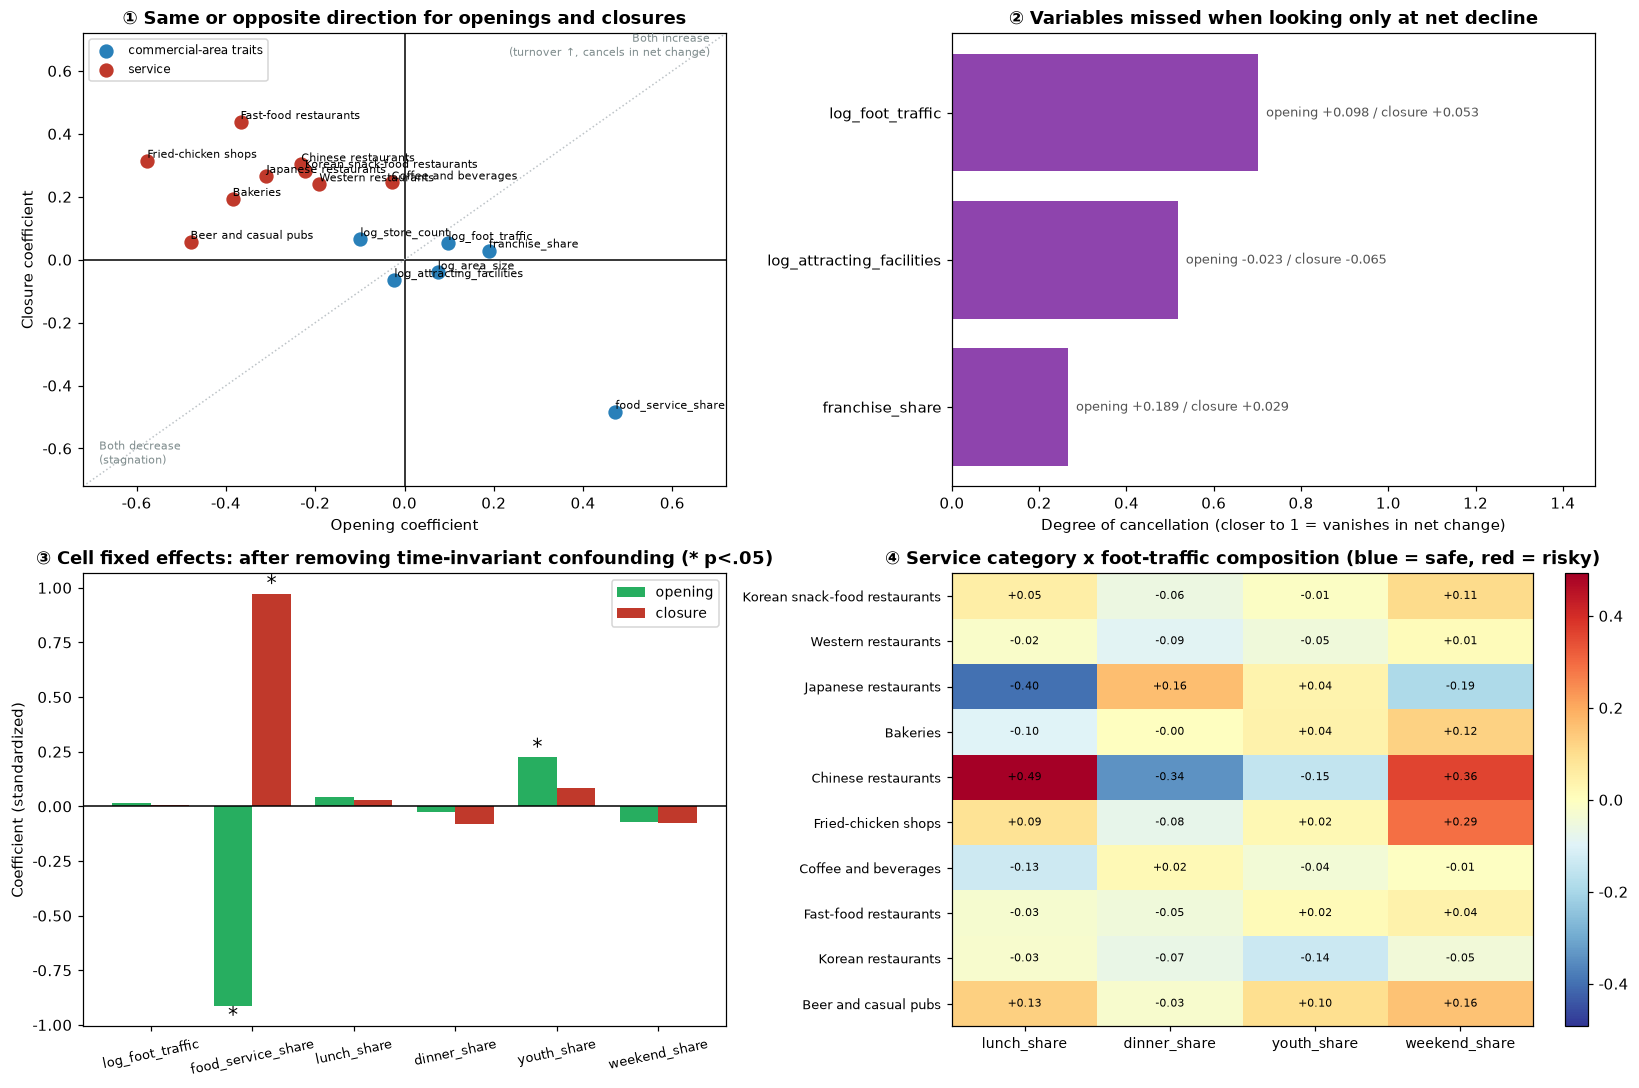

In [11]:
fig, ax = plt.subplots(2, 2, figsize=(15, 10))

# ① Opening vs closure coefficient scatter
s = cmp2.loc[[i for i in cmp2.index if not i.startswith("svc_")]]
sv = cmp2.loc[[i for i in cmp2.index if i.startswith("svc_")]]
ax[0,0].axhline(0, c="k", lw=1); ax[0,0].axvline(0, c="k", lw=1)
lim = max(cmp2[["opening_coef", "closure_coef"]].abs().max()) * 1.25
ax[0,0].plot([-lim, lim], [-lim, lim], ls=":", c="#bdc3c7", lw=1)
ax[0,0].scatter(s["opening_coef"], s["closure_coef"], s=70, c="#2980b9", label="commercial-area traits", zorder=3)
ax[0,0].scatter(sv["opening_coef"], sv["closure_coef"], s=70, c="#c0392b", label="service", zorder=3)
for i, r in cmp2.iterrows():
    ax[0,0].annotate(i.replace("svc_", ""), (r["opening_coef"], r["closure_coef"]),
                     fontsize=7.5, ha="left", va="bottom")
ax[0,0].set_xlim(-lim, lim); ax[0,0].set_ylim(-lim, lim)
ax[0,0].set_xlabel("Opening coefficient"); ax[0,0].set_ylabel("Closure coefficient")
ax[0,0].set_title("① Same or opposite direction for openings and closures", weight="bold")
ax[0,0].legend(fontsize=8)
ax[0,0].text(lim*.95, lim*.9, "Both increase\n(turnover ↑, cancels in net change)",
             fontsize=7.5, ha="right", color="#7f8c8d")
ax[0,0].text(-lim*.95, -lim*.9, "Both decrease\n(stagnation)", fontsize=7.5, ha="left", color="#7f8c8d")

# ② Degree of cancellation
t2 = sig[sig["offset_ratio"] > .01].sort_values("offset_ratio")
ax[0,1].barh([i.replace("svc_", "") for i in t2.index], t2["offset_ratio"], color="#8e44ad")
for k, (i, r) in enumerate(t2.iterrows()):
    ax[0,1].text(r["offset_ratio"], k, f"  opening {r['opening_coef']:+.3f} / closure {r['closure_coef']:+.3f}",
                 va="center", fontsize=8.5, color="#555")
ax[0,1].set_xlim(0, t2["offset_ratio"].max() * 2.1)
ax[0,1].set_xlabel("Degree of cancellation (closer to 1 = vanishes in net change)")
ax[0,1].set_title("② Variables missed when looking only at net decline", weight="bold")

# ③ Cell fixed effects
x = np.arange(len(TV_FE)); w = .38
ax[1,0].bar(x - w/2, fe["opening_coef"], w, label="opening", color="#27ae60")
ax[1,0].bar(x + w/2, fe["closure_coef"], w, label="closure", color="#c0392b")
for k, v in enumerate(TV_FE):
    for off_, col in [(-w/2, "opening_p"), (w/2, "closure_p")]:
        if fe.loc[v, col] < .05:
            yv = fe.loc[v, col.replace("_p", "_coef")]
            ax[1,0].text(x[k] + off_, yv, "*", ha="center",
                         va="bottom" if yv > 0 else "top", fontsize=13)
ax[1,0].axhline(0, c="k", lw=1)
ax[1,0].set_xticks(x); ax[1,0].set_xticklabels(TV_FE, fontsize=8.5, rotation=12)
ax[1,0].set_ylabel("Coefficient (standardized)")
ax[1,0].set_title("③ Cell fixed effects: after removing time-invariant confounding (* p<.05)", weight="bold")
ax[1,0].legend(fontsize=9)

# ④ Service category x composition heatmap
hm = grid[INTER]
im = ax[1,1].imshow(hm.values, cmap="RdYlBu_r", aspect="auto",
                    vmin=-np.abs(hm.values).max(), vmax=np.abs(hm.values).max())
ax[1,1].set_xticks(range(len(INTER))); ax[1,1].set_xticklabels(INTER, fontsize=9)
ax[1,1].set_yticks(range(len(hm))); ax[1,1].set_yticklabels(hm.index, fontsize=8.5)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        ax[1,1].text(j, i, f"{hm.values[i,j]:+.2f}", ha="center", va="center", fontsize=7.5)
ax[1,1].set_title("④ Service category x foot-traffic composition (blue = safe, red = risky)", weight="bold")
fig.colorbar(im, ax=ax[1,1], fraction=.046)

plt.tight_layout()
plt.savefig(FIG / "step10_extended.png", dpi=130)
plt.show()

## 10-6. Save and wrap up

In [12]:
cmp.to_csv(OUT / "q2_open_close.csv", encoding="utf-8-sig")
fe.to_csv(OUT / "q2_cell_fe.csv", encoding="utf-8-sig")
grid.to_csv(OUT / "q2_flow_interaction.csv", encoding="utf-8-sig")
gm.to_pickle(PROC / "10_extended.pkl")
print(f"[Saved] 10_extended.pkl  {gm.shape}")
print("[Saved] outputs/q2_open_close.csv, q2_cell_fe.csv, q2_flow_interaction.csv")
print("[Saved] figures/step10_extended.png\n")

flow_open = cmp.loc["log_foot_traffic", "opening_coef"]
flow_close = cmp.loc["log_foot_traffic", "closure_coef"]
print("=" * 62)
print("Sub-question 2: what STEP 10 added")
print("-" * 62)
print(f"① Foot traffic: opening {flow_open:+.3f} (p={cmp.loc['log_foot_traffic','opening_p']:.3f}) · "
      f"closure {flow_close:+.3f} (p={cmp.loc['log_foot_traffic','closure_p']:.3f})")
print("   -> Same direction for both. It cancelled in the net change (difference) and so looked 'unrelated'.")
print("   -> A commercial area with high foot traffic is not risky; it has **fast turnover**.")
print(f"② With cell fixed effects, foot traffic: opening p={fe.loc['log_foot_traffic','opening_p']:.3f} · "
      f"closure p={fe.loc['log_foot_traffic','closure_p']:.3f}")
print("   -> Even when foot traffic changes within the same cell, the opening and closure rates do not move.")
print("   -> The cross-sectional association is produced by time-invariant characteristics of the commercial area.")
print("③ Foot-traffic composition works in a different direction for each service category (see the 10-4 tables)")
print("=" * 62)

[Saved] 10_extended.pkl  (31875, 50)
[Saved] outputs/q2_open_close.csv, q2_cell_fe.csv, q2_flow_interaction.csv
[Saved] figures/step10_extended.png

Sub-question 2: what STEP 10 added
--------------------------------------------------------------
① Foot traffic: opening +0.098 (p=0.000) · closure +0.053 (p=0.010)
   -> Same direction for both. It cancelled in the net change (difference) and so looked 'unrelated'.
   -> A commercial area with high foot traffic is not risky; it has **fast turnover**.
② With cell fixed effects, foot traffic: opening p=0.865 · closure p=0.963
   -> Even when foot traffic changes within the same cell, the opening and closure rates do not move.
   -> The cross-sectional association is produced by time-invariant characteristics of the commercial area.
③ Foot-traffic composition works in a different direction for each service category (see the 10-4 tables)


---

## What this step changed

- **"Scale is risky"** → decomposed into **two paths**: fewer openings and more closures
- **"Foot traffic is unrelated"** → it raises openings and closures **together, so they cancel**. Not unrelated, but turnover
- **"Commercial-area level, so service categories cannot be distinguished"** → true for total volume, but the **composition x service category interaction** is identifiable

## Remaining limitations

- `food_service_share` includes the cell's own stores. In the cell fixed-effects model it could be recomputed excluding the cell itself
- Composition shares also have 85-99% between-commercial-area variance, so power is low under cell fixed effects
- The stock-flow problem of conditional logistic was sidestepped, not solved. The fundamental fix is **store-level data**